# Prediksi Beban Energi Pemanas dan Pendingin Bangunan | Multivariate Linear Regression

---


## 1. BUSINESS UNDERSTANDING

### 1.1 Latar Belakang, Masalah, dan Solusi
* **Latar Belakang**: Sebuah perusahaan konsultan arsitektur dan efisiensi energi bangunan bertugas merancang gedung-gedung modern yang hemat energi dan ramah lingkungan. Dalam tahap pra-konstruksi, arsitek dan teknisi HVAC perlu mengestimasi besaran beban pemanas ruangan (`Heating_Load`) dan beban pendingin ruangan (`Cooling_Load`) berdasarkan parameter fisik dan geometris bangunan.
* **Masalah**: Simulasi secara manual menggunakan perangkat lunak fisika bangunan memakan waktu komputasi yang sangat lama, rumit, dan membutuhkan ribuan input detail material yang belum tersedia pada fase awal perancangan. Algoritma regresi linier standar hanya mampu memodelkan satu variabel target secara terpisah. Akibatnya, tim konsultan harus melatih dua model independen yang tidak memanfaatkan korelasi bawaan antara beban pemanas dan beban pendingin, sehingga proses pemodelan menjadi redundan dan kurang efisien.
* **Solusi**: Membangun model *machine learning* berbasis **Multivariate Linear Regression** yang memanfaatkan aljabar linier matriks OLS Normal Equation ($B = (X^T X)^{-1} X^T Y$) untuk memprediksi dua variabel target sekaligus (`Heating_Load` dan `Cooling_Load`)  dalam satu kali operasi komputasi.

### 1.2 Deskripsi Kolom Dataset

| Nama Kolom | Simbol | Tipe Data | Rentang Nilai |
| :--- | :---: | :---: | :---: |
| **`Relative_Compactness`** | $x_1$ | `float64` | 0.62 s.d. 0.98 |
| **`Surface_Area`** | $x_2$ | `float64` | 514.5 s.d. 808.5 $\text{m}^2$ |
| **`Wall_Area`** | $x_3$ | `float64` | 245.0 s.d. 416.5 $\text{m}^2$ |
| **`Roof_Area`** | $x_4$ | `float64` | 110.25 s.d. 220.5 $\text{m}^2$ |
| **`Overall_Height`** | $x_5$ | `float64` | 3.5 m atau 7.0 m |
| **`Orientation`** | $x_6$ | `int64` | Kode 2, 3, 4, 5 |
| **`Glazing_Area`** | $x_7$ | `float64` | 0.00 s.d. 0.40 |
| **`Glazing_Area_Distribution`** | $x_8$ | `int64` | Skala 0 s.d. 5 |
| **`Heating_Load`** | $y_1$ | `float64` | 6.01 s.d. 43.10 $\text{kWh/m}^2$ |
| **`Cooling_Load`** | $y_2$ | `float64` | 10.90 s.d. 48.03 $\text{kWh/m}^2$ |

---


## 2. DATA PREPARATION


### 2.1 Import Library
Mengimpor pustaka utama untuk komputasi numerik (`numpy`), pemrosesan data tabular (`pandas`), visualisasi grafis (`matplotlib.pyplot`, `seaborn`).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

### 2.2 Pemuatan Dataset


In [2]:
df = pd.read_csv('energy_efficiency_data.csv')

### 2.3 Menampilkan Sampel Data Teratas & Terbawah


In [3]:
df.head()

,Relative_Compactness,Surface_Area,Wall_Area,Roof_Area,Overall_Height,Orientation,Glazing_Area,Glazing_Area_Distribution,Heating_Load,Cooling_Load
0,0.98,514.5,294.0,110.25,7.0,2,0.0,0,15.55,21.33
1,0.98,514.5,294.0,110.25,7.0,3,0.0,0,15.55,21.33
2,0.98,514.5,294.0,110.25,7.0,4,0.0,0,15.55,21.33
3,0.98,514.5,294.0,110.25,7.0,5,0.0,0,15.55,21.33
4,0.90,563.5,318.5,122.50,7.0,2,0.0,0,20.84,28.28


In [4]:
df.tail()

,Relative_Compactness,Surface_Area,Wall_Area,Roof_Area,Overall_Height,Orientation,Glazing_Area,Glazing_Area_Distribution,Heating_Load,Cooling_Load
763,0.64,784.0,343.0,220.5,3.5,5,0.4,5,17.88,21.40
764,0.62,808.5,367.5,220.5,3.5,2,0.4,5,16.54,16.88
765,0.62,808.5,367.5,220.5,3.5,3,0.4,5,16.44,17.11
766,0.62,808.5,367.5,220.5,3.5,4,0.4,5,16.48,16.61
767,0.62,808.5,367.5,220.5,3.5,5,0.4,5,16.64,16.03


### 2.4 Pemeriksaan Dimensi, Ukuran Elemen, Missing Value, dan Duplikasi

In [5]:
print("Dimensi Data:", df.shape)
print("Total Elemen Data:", df.size)
print("\n--- Jumlah Missing Value per Kolom ---")
print(df.isnull().sum())
print("\nTotal Missing Value Keseluruhan :", df.isnull().sum().sum())
print("Jumlah Baris Duplikat :", df.duplicated().sum())

Dimensi Data: (768, 10)
Total Elemen Data: 7680

--- Jumlah Missing Value per Kolom ---
Relative_Compactness         0
Surface_Area                 0
Wall_Area                    0
Roof_Area                    0
Overall_Height               0
Orientation                  0
Glazing_Area                 0
Glazing_Area_Distribution    0
Heating_Load                 0
Cooling_Load                 0
dtype: int64

Total Missing Value Keseluruhan : 0
Jumlah Baris Duplikat : 0


### 2.5 Ringkasan Struktur dan Tipe Data


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 10 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Relative_Compactness       768 non-null    float64
 1   Surface_Area               768 non-null    float64
 2   Wall_Area                  768 non-null    float64
 3   Roof_Area                  768 non-null    float64
 4   Overall_Height             768 non-null    float64
 5   Orientation                768 non-null    int64  
 6   Glazing_Area               768 non-null    float64
 7   Glazing_Area_Distribution  768 non-null    int64  
 8   Heating_Load               768 non-null    float64
 9   Cooling_Load               768 non-null    float64
dtypes: float64(8), int64(2)
memory usage: 60.1 KB


### 2.6 Analisis Nilai Unik dan Karakteristik Fitur
Memeriksa variasi nilai unik pada setiap fitur arsitektur bangunan untuk memahami desain eksperimental simulasi.

In [7]:
unique = []
for col in df.columns:
    unique.append({
        'Nama Kolom': col,
        'Dtype': str(df[col].dtype),
        'Non-Null': df[col].count(),
        'Missing': df[col].isnull().sum(),
        'Unik': df[col].nunique(),
        'Sampel Nilai Unik': sorted(df[col].unique()[:6].tolist())
    })

pd.DataFrame(unique)

,Nama Kolom,Dtype,Non-Null,Missing,Unik,Sampel Nilai Unik
0,Relative_Compactness,float64,768,0,12,"[0.76, 0.79, 0.82, 0.86, 0.9, 0.98]"
1,Surface_Area,float64,768,0,12,"[514.5, 563.5, 588.0, 612.5, 637.0, 661.5]"
2,Wall_Area,float64,768,0,7,"[245.0, 269.5, 294.0, 318.5, 343.0, 416.5]"
3,Roof_Area,float64,768,0,4,"[110.25, 122.5, 147.0, 220.5]"
4,Overall_Height,float64,768,0,2,"[3.5, 7.0]"
5,Orientation,int64,768,0,4,"[2, 3, 4, 5]"
6,Glazing_Area,float64,768,0,4,"[0.0, 0.1, 0.25, 0.4]"
7,Glazing_Area_Distribution,int64,768,0,6,"[0, 1, 2, 3, 4, 5]"
8,Heating_Load,float64,768,0,586,"[15.55, 19.5, 19.68, 20.71, 20.84, 21.46]"
9,Cooling_Load,float64,768,0,636,"[21.33, 25.16, 25.38, 27.3, 28.28, 29.6]"


Dataset terdiri atas **768 baris** dan **10 kolom** sehingga total menjadi 7.680 data. Seluruh fitur bertipe numerik (`float64` dan `int64`). Dataset berstatus bersih sempurna tanpa nilai hilang dan tanpa duplikasi data.

---

## 3. EXPLORATORY DATA ANALYSIS (EDA)

### 3.1 Analisis Deteksi Outlier (Metode IQR & Z-Score)


In [8]:
outliers = []
for col in df.columns:
    q1 = df[col].quantile(0.25)
    median = df[col].median()
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    iqr_outlier = df[(df[col] < lower) | (df[col] > upper)]
    mean = df[col].mean()
    std = df[col].std()
    z_score = (df[col] - mean) / std
    z_outlier = df[np.abs(z_score) > 3]
    
    outliers.append({
        'Nama Kolom': col,
        'Mean': mean,
        'Standarisasi': std,
        'Min': df[col].min(),
        'Q1': q1,
        'Median': median,
        'Q3': q3,
        'Max': df[col].max(),
        'Batas Bawah IQR': lower,
        'Batas Atas IQR': upper,
        'Outlier IQR': len(iqr_outlier),
        'Outlier Z-Score': len(z_outlier)
    })

pd.DataFrame(outliers)

,Nama Kolom,Mean,Standarisasi,Min,Q1,Median,Q3,Max,Batas Bawah IQR,Batas Atas IQR,Outlier IQR,Outlier Z-Score
0,Relative_Compactness,0.764167,0.105777,0.62,0.6825,0.75,0.8300,0.98,0.46125,1.05125,0,0
1,Surface_Area,671.708333,88.086116,514.50,606.3750,673.75,741.1250,808.50,404.25000,943.25000,0,0
2,Wall_Area,318.500000,43.626481,245.00,294.0000,318.50,343.0000,416.50,220.50000,416.50000,0,0
3,Roof_Area,176.604167,45.165950,110.25,140.8750,183.75,220.5000,220.50,21.43750,339.93750,0,0
4,Overall_Height,5.250000,1.751140,3.50,3.5000,5.25,7.0000,7.00,-1.75000,12.25000,0,0
5,Orientation,3.500000,1.118763,2.00,2.7500,3.50,4.2500,5.00,0.50000,6.50000,0,0
6,Glazing_Area,0.234375,0.133221,0.00,0.1000,0.25,0.4000,0.40,-0.35000,0.85000,0,0
7,Glazing_Area_Distribution,2.812500,1.550960,0.00,1.7500,3.00,4.0000,5.00,-1.62500,7.37500,0,0
8,Heating_Load,22.307201,10.090196,6.01,12.9925,18.95,31.6675,43.10,-15.02000,59.68000,0,0
9,Cooling_Load,24.587760,9.513306,10.90,15.6200,22.08,33.1325,48.03,-10.64875,59.40125,0,0


### 3.2 Visualisasi Distribusi Target & Analisis Outlier

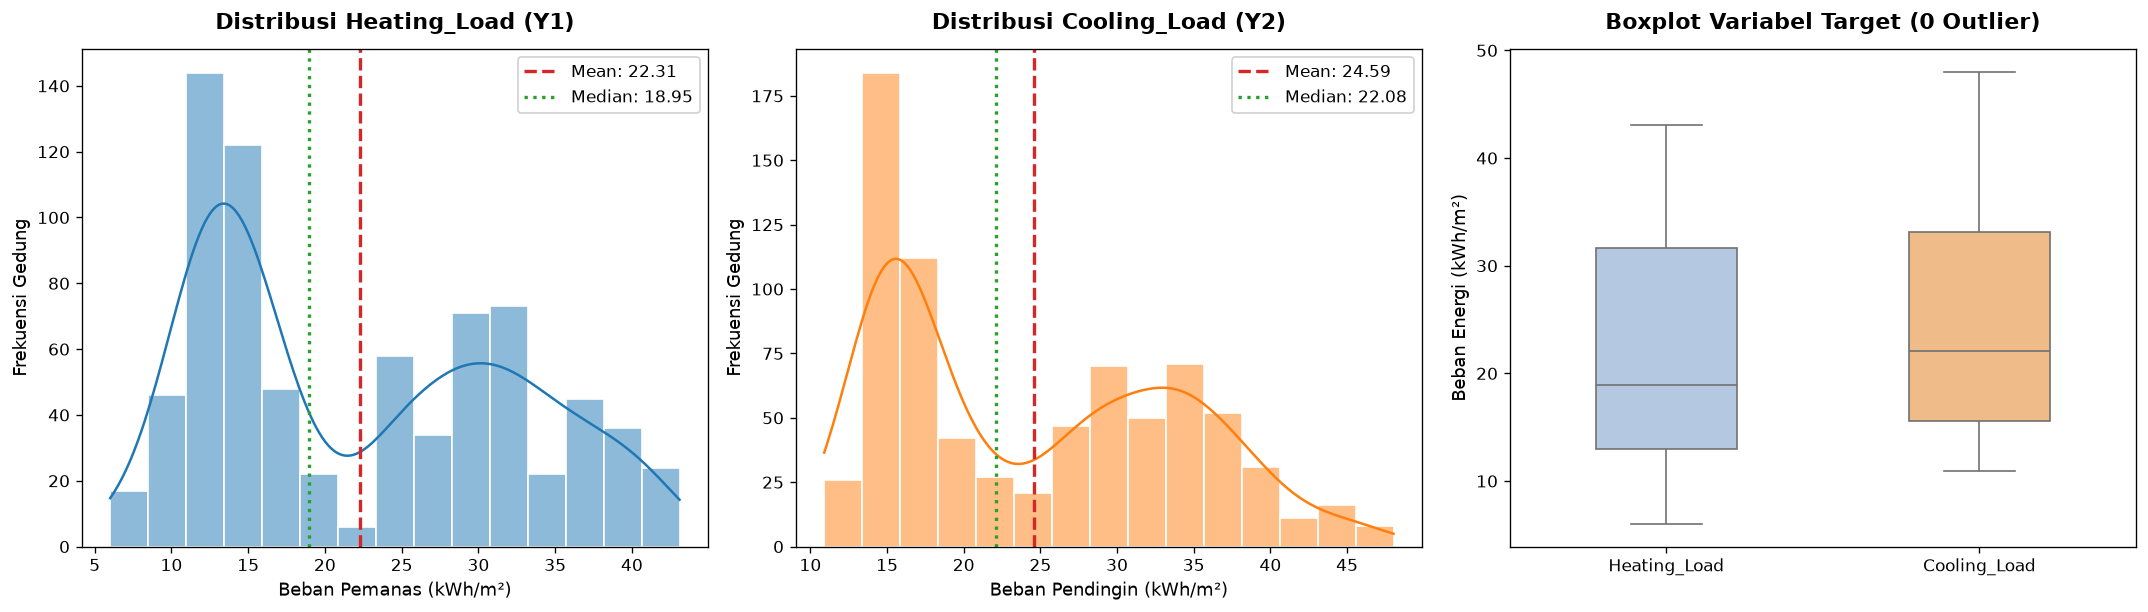

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5.2), dpi=120)

sns.histplot(df['Heating_Load'], kde=True, ax=axes[0], color='#1f77b4', bins=15, edgecolor='white')
axes[0].axvline(df['Heating_Load'].mean(), color='#d62728', linestyle='--', linewidth=2, label=f"Mean: {df['Heating_Load'].mean():.2f}")
axes[0].axvline(df['Heating_Load'].median(), color='#2ca02c', linestyle=':', linewidth=2, label=f"Median: {df['Heating_Load'].median():.2f}")
axes[0].set_title('Distribusi Heating_Load (Y1)', fontsize=13, fontweight='bold', pad=12)
axes[0].set_xlabel('Beban Pemanas (kWh/m²)', fontsize=11)
axes[0].set_ylabel('Frekuensi Gedung', fontsize=11)
axes[0].legend(frameon=True, facecolor='white', framealpha=0.9)

sns.histplot(df['Cooling_Load'], kde=True, ax=axes[1], color='#ff7f0e', bins=15, edgecolor='white')
axes[1].axvline(df['Cooling_Load'].mean(), color='#d62728', linestyle='--', linewidth=2, label=f"Mean: {df['Cooling_Load'].mean():.2f}")
axes[1].axvline(df['Cooling_Load'].median(), color='#2ca02c', linestyle=':', linewidth=2, label=f"Median: {df['Cooling_Load'].median():.2f}")
axes[1].set_title('Distribusi Cooling_Load (Y2)', fontsize=13, fontweight='bold', pad=12)
axes[1].set_xlabel('Beban Pendingin (kWh/m²)', fontsize=11)
axes[1].set_ylabel('Frekuensi Gedung', fontsize=11)
axes[1].legend(frameon=True, facecolor='white', framealpha=0.9)

sns.boxplot(data=df[['Heating_Load', 'Cooling_Load']], ax=axes[2], palette=['#aec7e8', '#ffbb78'], width=0.45)
axes[2].set_title('Boxplot Variabel Target (0 Outlier)', fontsize=13, fontweight='bold', pad=12)
axes[2].set_ylabel('Beban Energi (kWh/m²)', fontsize=11)

plt.tight_layout()
plt.show()

### 3.3 Analisis Korelasi

In [10]:
selisih_geometris = df['Surface_Area'] - (df['Wall_Area'] + 2 * df['Roof_Area'])
print("Selisih Maksimum pada 768 baris :", np.max(np.abs(selisih_geometris)))

Selisih Maksimum pada 768 baris : 0.0


### 3.4 Visualisasi Heatmap Korelasi & Scatter Plot 

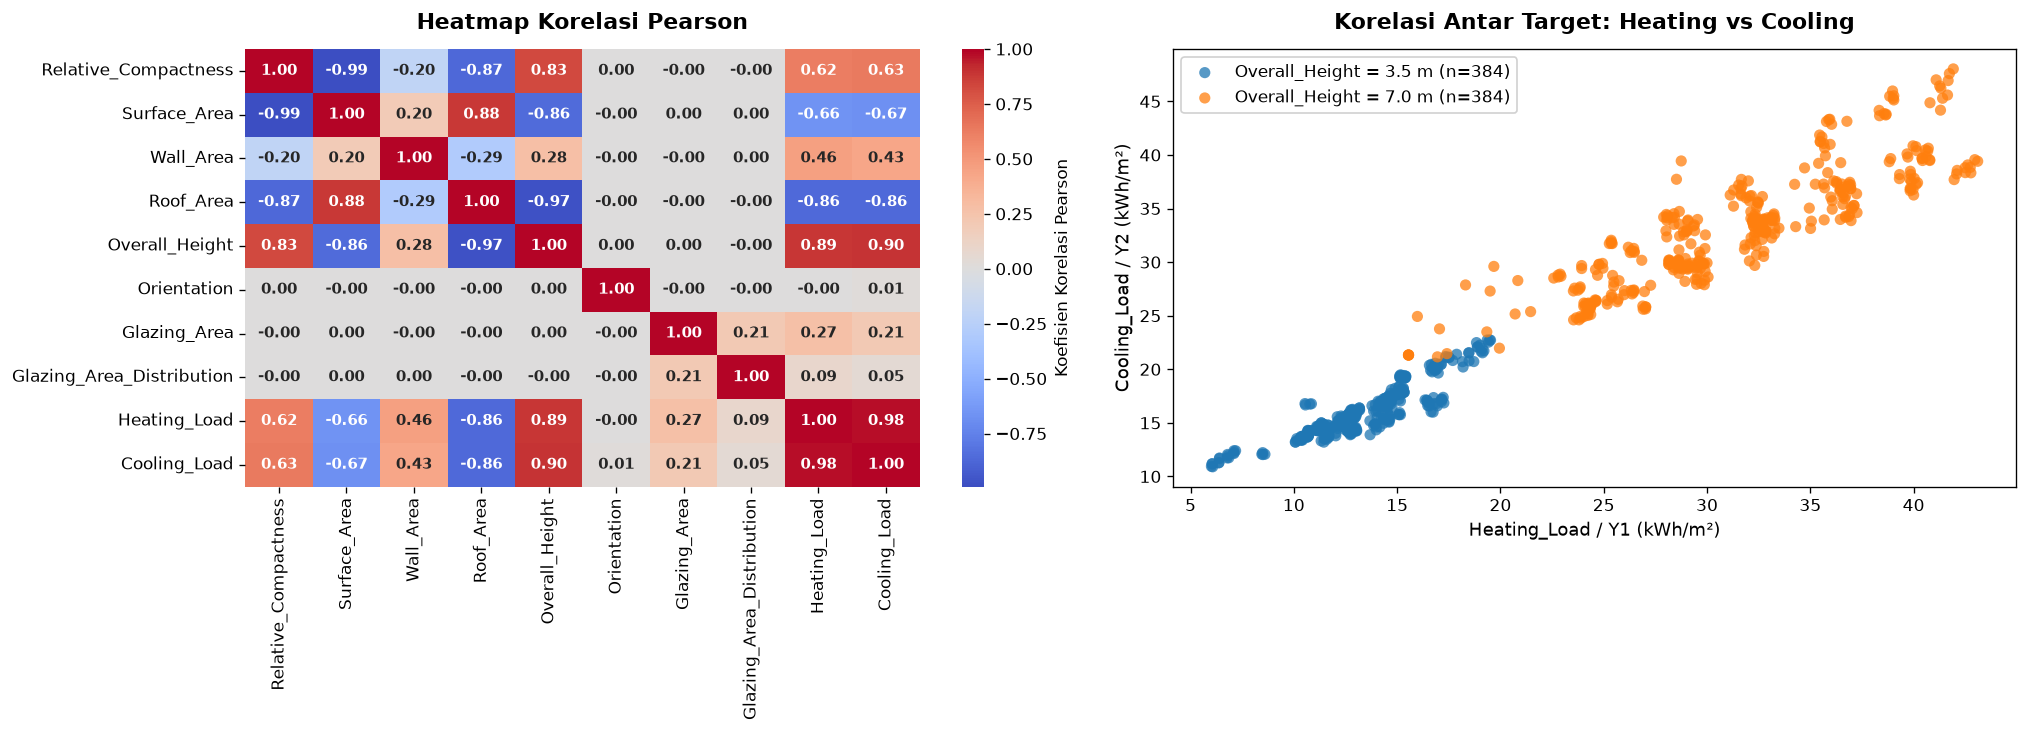

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(17, 6.2), dpi=120)

corr_10x10 = df.corr(method='pearson')
sns.heatmap(corr_10x10, annot=True, fmt='.2f', cmap='coolwarm', center=0, ax=axes[0],
            cbar_kws={'label': 'Koefisien Korelasi Pearson'}, annot_kws={'size': 9, 'weight': 'bold'})
axes[0].set_title('Heatmap Korelasi Pearson', fontsize=13, fontweight='bold', pad=12)

palette_height = {3.5: '#1f77b4', 7.0: '#ff7f0e'}
for h_val, color in palette_height.items():
    subset = df[df['Overall_Height'] == h_val]
    axes[1].scatter(subset['Heating_Load'], subset['Cooling_Load'], color=color, s=45, alpha=0.75,
                    label=f'Overall_Height = {h_val:.1f} m (n={len(subset)})', edgecolor='none')

axes[1].set_title('Korelasi Antar Target: Heating vs Cooling', fontsize=13, fontweight='bold', pad=12)
axes[1].set_xlabel('Heating_Load / Y1 (kWh/m²)', fontsize=11)
axes[1].set_ylabel('Cooling_Load / Y2 (kWh/m²)', fontsize=11)
axes[1].legend(frameon=True, facecolor='white', framealpha=0.9)

plt.tight_layout()
plt.show()

---

## 4. DATA PREPROCESSING

### 4.1 Dimensi Data Latih dan Data Uji

In [12]:
feature_cols = ['Relative_Compactness', 'Surface_Area', 'Wall_Area', 'Roof_Area',
                'Overall_Height', 'Orientation', 'Glazing_Area', 'Glazing_Area_Distribution']
target_cols = ['Heating_Load', 'Cooling_Load']

X = df[feature_cols].values
Y = df[target_cols].values

np.random.seed(42)
perm_indices = np.random.permutation(len(df))
train_idx = perm_indices[:614]
test_idx = perm_indices[614:]

X_train, Y_train = X[train_idx], Y[train_idx]
X_test, Y_test = X[test_idx], Y[test_idx]

mean_train = X_train.mean(axis=0)
std_train = X_train.std(axis=0, ddof=1)

X_train_s = (X_train - mean_train) / std_train
X_test_s = (X_test - mean_train) / std_train

print("Dimensi Data Training (X, Y) :", X_train.shape, Y_train.shape)
print("Dimensi Data Testing  (X, Y) :", X_test.shape, Y_test.shape)

Dimensi Data Training (X, Y) : (614, 8) (614, 2)
Dimensi Data Testing  (X, Y) : (154, 8) (154, 2)


### 4.2 Analisis Angka Kondisi Matriks $X^T X$
Memeriksa angka kondisi matriks $(X^T X)$ pada data mentah vs terstandarisasi untuk mendiagnosis tingkat kesakitan matriks.

In [13]:
def bias(x):
    return np.c_[np.ones(x.shape[0]), x]

cond_raw = np.linalg.cond(bias(X_train).T @ bias(X_train))
cond_scaled = np.linalg.cond(bias(X_train_s).T @ bias(X_train_s))

feat_7_idx = [0, 1, 2, 4, 5, 6, 7]
cond_7_scaled = np.linalg.cond(bias(X_train_s[:, feat_7_idx]).T @ bias(X_train_s[:, feat_7_idx]))

print(f"Condition Number Matriks X^T X: {cond_raw:.2e}")
print(f"Condition Number Matriks X^T X: {cond_scaled:.2e}")
print(f"Condition Number Matriks X^T X: {cond_7_scaled:.2f}")

Condition Number Matriks X^T X: 8.00e+18
Condition Number Matriks X^T X: 8.50e+14
Condition Number Matriks X^T X: 904.84


## 5. MODELLING MULTIVARIATE LINEAR REGRESSION

model Multivariate Linear Regression dirumuskan dalam persamaan matriks tunggal:
$$Y = X B + E$$
Dengan rincian dimensi pada data training ($n = 614$ sampel, $k = 8$ fitur independen, $m = 2$ target dependen):
* **Matriks Desain $X$**: Berukuran $n \times (k + 1) \rightarrow 614 \times 9$ (kolom pertama berisi vektor angka 1 untuk bias intercept $\beta_0$).
* **Matriks Target $Y$**: Berukuran $n \times m \rightarrow 614 \times 2$ (kolom 1: `Heating_Load`, kolom 2: `Cooling_Load`).
* **Matriks Koefisien $B$**: Berukuran $(k + 1) \times m \rightarrow 9 \times 2$ (menghitung seluruh koefisien kedua target secara simultan).
* **Matriks Galat $E$**: Berukuran $n \times m \rightarrow 614 \times 2$ ($E = Y - \hat{Y}$).

Solusi analitis Ordinary Least Squares (OLS) Normal Equation Multi-Target:
$$B = (X^T X)^{-1} X^T Y$$
Prediksi serentak pada data uji:
$$\hat{Y}_{test} = X_{test\_b} B$$

### 5.1 Implementasi Fungsi Matriks Multivariate Linear Regression

In [14]:
def multivariate_linear_regression(X_train, Y_train, X_test):
    mean = X_train.mean(axis=0)
    std = X_train.std(axis=0, ddof=1)
    X_train_s = (X_train - mean) / std
    X_test_s = (X_test - mean) / std
    X_train_b = bias(X_train_s)
    X_test_b = bias(X_test_s)
    B = np.linalg.pinv(X_train_b.T @ X_train_b) @ (X_train_b.T @ Y_train)
    Y_pred = X_test_b @ B
    Y_pred_train = X_train_b @ B
    return B, Y_pred, Y_pred_train

### 5.2 Pelatihan Model & Ekstraksi Matriks Koefisien $B$
Melatih model Multivariate Linear Regression pada data training dan mengekstraksi matriks parameter koefisien $B$ pada skala terstandarisasi serta skala asli ($kWh/m^2$).

In [15]:
B_matrix, Y_pred_test, Y_pred_train = multivariate_linear_regression(X_train, Y_train, X_test)

b_orig_slope = B_matrix[1:, :] / std_train[:, None]
b_orig_intercept = B_matrix[0, :] - np.sum(B_matrix[1:, :] * mean_train[:, None] / std_train[:, None], axis=0)

B_unscaled_direct = np.linalg.pinv(bias(X_train).T @ bias(X_train)) @ (bias(X_train).T @ Y_train)

param = ['beta_0 Intercept'] + [f'beta_{i+1} {col}' for i, col in enumerate(feature_cols)]

koefisien = []
for i in range(9):
    koefisien.append({
        'Parameter': param[i],
        'Bobot Standar Y1': f"{B_matrix[i, 0]:+.4f}",
        'Bobot Standar Y2': f"{B_matrix[i, 1]:+.4f}",
        'Bobot Skala Asli Y1': f"{B_unscaled_direct[i, 0]:+.4f}",
        'Bobot Skala Asli Y2': f"{B_unscaled_direct[i, 1]:+.4f}",
    })

pd.DataFrame(koefisien)

,Parameter,Bobot Standar Y1,Bobot Standar Y2,Bobot Skala Asli Y1,Bobot Skala Asli Y2
0,beta_0 Intercept,+22.6561,+24.8673,+91.4928,+102.2528
1,beta_1 Relative_Compactness,-7.3181,-7.7632,-69.2798,-73.4937
2,beta_2 Surface_Area,-4.0459,-4.1600,-0.0674,-0.0694
3,beta_3 Wall_Area,+0.6378,+0.0105,+0.0362,+0.0225
4,beta_4 Roof_Area,-4.2729,-4.0828,-0.0519,-0.0461
5,beta_5 Overall_Height,+7.2952,+7.4469,+4.1661,+4.2527
6,beta_6 Orientation,-0.0859,+0.1185,-0.0766,+0.1056
7,beta_7 Glazing_Area,+2.5952,+1.9195,+19.5009,+14.4232
8,beta_8 Glazing_Area_Distribution,+0.3055,+0.0458,+0.1981,+0.0297


---
## 6. EVALUATION

### 6.1 Implementasi Fungsi Evaluasi Metrik Regresi

In [ ]:
def hitung_metrik_regresi(y_true, y_pred, k):
    n = len(y_true)
    mse = np.mean((y_true - y_pred)**2)
    rmse = np.sqrt(mse)
    mae = np.mean(np.abs(y_true - y_pred))
    ss_tot = np.sum((y_true - y_true.mean())**2)
    ss_res = np.sum((y_true - y_pred)**2)
    r2 = 1 - (ss_res / ss_tot)
    adj_r2 = 1 - (1 - r2) * (n - 1) / (n - k - 1)
    return r2, adj_r2, mse, rmse, mae

### 6.2 Ringkasan Metrik Kinerja Model Utama (OLS Stabil)

In [27]:
eval_hasil = []
for j, tgt in enumerate(target_cols):
    r2_tr, _, _, _, mae_tr = hitung_metrik_regresi(Y_train[:, j], Y_pred_train[:, j], 8)
    r2_te, adj_te, mse_te, rmse_te, mae_te = hitung_metrik_regresi(Y_test[:, j], Y_pred_test[:, j], 8)
    eval_hasil.append({
        'Variabel Target': tgt,
        'R2 Train': r2_tr,
        'R2 Test': r2_te,
        'Adj. R2 Test': adj_te,
        'MSE Test': mse_te,
        'RMSE Test': rmse_te,
        'MAE Test': mae_te,
        'MAE Train': mae_tr
    })

eval_df = pd.DataFrame(eval_hasil)
rata_rata_row = {
    'Variabel Target': 'Rata-Rata Gabungan (Y1 & Y2)',
    'R2 Train': eval_df['R2 Train'].mean(),
    'R2 Test': eval_df['R2 Test'].mean(),
    'Adj. R2 Test': eval_df['Adj. R2 Test'].mean(),
    'MSE Test': eval_df['MSE Test'].mean(),
    'RMSE Test': eval_df['RMSE Test'].mean(),
    'MAE Test': eval_df['MAE Test'].mean(),
    'MAE Train': eval_df['MAE Train'].mean()
}
eval_df = pd.concat([eval_df, pd.DataFrame([rata_rata_row])], ignore_index=True)

eval_df_formatted = eval_df.copy()
for col in ['R2 Train', 'R2 Test', 'Adj. R2 Test', 'MSE Test', 'RMSE Test', 'MAE Test', 'MAE Train']:
    eval_df_formatted[col] = eval_df_formatted[col].apply(lambda x: f"{x:.4f}")

eval_df_formatted

,Variabel Target,R2 Train,R2 Test,Adj. R2 Test,MSE Test,RMSE Test,MAE Test,MAE Train
0,Heating_Load,0.9172,0.9075,0.9024,8.1266,2.8507,2.0212,2.0866
1,Cooling_Load,0.8898,0.8763,0.8695,10.1077,3.1793,2.1794,2.2665
2,Rata-Rata Gabungan (Y1 & Y2),0.9035,0.8919,0.8859,9.1172,3.0150,2.1003,2.1766


### 6.3 Visualisasi Evaluasi Model Multi-Target
* Scatter plot Nilai Aktual vs Nilai Prediksi pada data testing ($n=154$) untuk `Heating_Load` ($R^2 = 0.9075$) dan `Cooling_Load` ($R^2 = 0.8763$), dengan garis putus-putus merah $y_{pred} = y_{test}$ sebagai acuan prediksi sempurna.
* Diagram batang  yang membandingkan bobot koefisien terstandarisasi ($\beta_{std}$) antara target `Heating_Load` dan `Cooling_Load`.

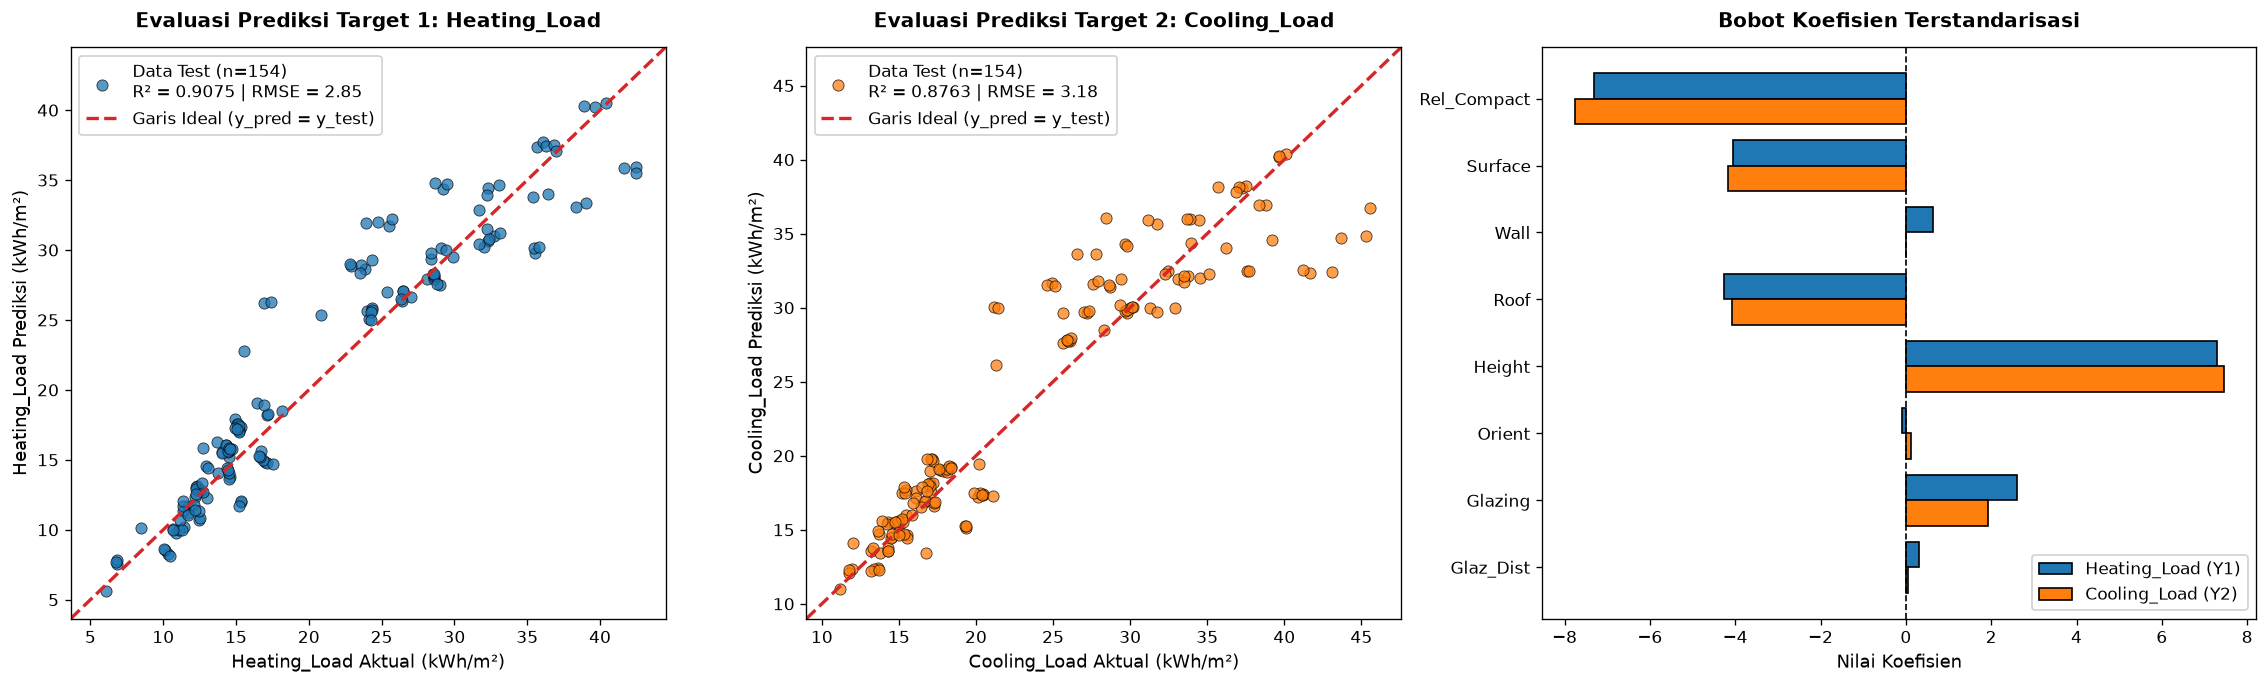

In [ ]:
fig = plt.figure(figsize=(19, 5.8), dpi=120)
gs = fig.add_gridspec(1, 3, width_ratios=[1, 1, 1.2])

ax0 = fig.add_subplot(gs[0, 0])
ax0.scatter(Y_test[:, 0], Y_pred_test[:, 0], color='#1f77b4', s=45, alpha=0.75, edgecolor='black', linewidth=0.5, label='Data Test (n=154)\nR² = 0.9075 | RMSE = 2.85')
lims_0 = [min(Y_test[:, 0].min(), Y_pred_test[:, 0].min()) - 2, max(Y_test[:, 0].max(), Y_pred_test[:, 0].max()) + 2]
ax0.plot(lims_0, lims_0, color='#d62728', linestyle='--', linewidth=2, label='Garis Ideal (y_pred = y_test)')
ax0.set_xlim(lims_0)
ax0.set_ylim(lims_0)
ax0.set_title('Evaluasi Prediksi Target 1: Heating_Load', fontsize=12, fontweight='bold', pad=12)
ax0.set_xlabel('Heating_Load Aktual (kWh/m²)', fontsize=11)
ax0.set_ylabel('Heating_Load Prediksi (kWh/m²)', fontsize=11)
ax0.legend(loc='upper left', frameon=True, facecolor='white', framealpha=0.9)

ax1 = fig.add_subplot(gs[0, 1])
ax1.scatter(Y_test[:, 1], Y_pred_test[:, 1], color='#ff7f0e', s=45, alpha=0.75, edgecolor='black', linewidth=0.5, label='Data Test (n=154)\nR² = 0.8763 | RMSE = 3.18')
lims_1 = [min(Y_test[:, 1].min(), Y_pred_test[:, 1].min()) - 2, max(Y_test[:, 1].max(), Y_pred_test[:, 1].max()) + 2]
ax1.plot(lims_1, lims_1, color='#d62728', linestyle='--', linewidth=2, label='Garis Ideal (y_pred = y_test)')
ax1.set_xlim(lims_1)
ax1.set_ylim(lims_1)
ax1.set_title('Evaluasi Prediksi Target 2: Cooling_Load', fontsize=12, fontweight='bold', pad=12)
ax1.set_xlabel('Cooling_Load Aktual (kWh/m²)', fontsize=11)
ax1.set_ylabel('Cooling_Load Prediksi (kWh/m²)', fontsize=11)
ax1.legend(loc='upper left', frameon=True, facecolor='white', framealpha=0.9)

ax2 = fig.add_subplot(gs[0, 2])
feature_short_names = ['Rel_Compact', 'Surface', 'Wall', 'Roof', 'Height', 'Orient', 'Glazing', 'Glaz_Dist']
y_positions = np.arange(len(feature_short_names))
bar_width = 0.38

ax2.barh(y_positions - bar_width/2, B_matrix[1:, 0], height=bar_width, color='#1f77b4', edgecolor='black', label='Heating_Load (Y1)')
ax2.barh(y_positions + bar_width/2, B_matrix[1:, 1], height=bar_width, color='#ff7f0e', edgecolor='black', label='Cooling_Load (Y2)')
ax2.axvline(0, color='black', linestyle='--', linewidth=1)
ax2.set_yticks(y_positions)
ax2.set_yticklabels(feature_short_names, fontsize=10)
ax2.invert_yaxis()
ax2.set_title('Bobot Koefisien Terstandarisasi', fontsize=12, fontweight='bold', pad=12)
ax2.set_xlabel('Nilai Koefisien', fontsize=11)
ax2.legend(loc='lower right', frameon=True, facecolor='white', framealpha=0.9)

plt.tight_layout()
plt.show()

---

## 7. CONCLUSION 

### 7.1 Kesimpulan Analisis
   Algoritma **Multivariate Linear Regression** berhasil memprediksi kebutuhan energi pemanas (`Heating_Load`) dan pendingin (`Cooling_Load`) secara simultan dalam satu operasi matriks terpadu, mencapai rata-rata akurasi $R^2 = 0.8919$ dan rata-rata kesalahan absolut ($MAE$) hanya **$2.10\text{ kWh/m}^2$** ($R^2 = 90.75\%$ pada `Heating_Load` dan $87.63\%$ pada `Cooling_Load`). Eksperimen membuktikan bahwa hubungan geometris eksak $\text{Surface\_Area} = \text{Wall\_Area} + 2 \times \text{Roof\_Area}$ membuat matriks $X^T X$ mentah menjadi tidak stabil saat diinversi dengan `np.linalg.inv`.